In [3]:
!pip -q install gdown

In [4]:
import gdown

url = "https://drive.google.com/file/d/1eHChVwaAwG66p9eDhISOROPIvKXnMg9W/view"
output = "/kaggle/working/dataset.zip"

gdown.download(url, output, quiet=False, fuzzy=True)

Downloading...
From (original): https://drive.google.com/uc?id=1eHChVwaAwG66p9eDhISOROPIvKXnMg9W
From (redirected): https://drive.google.com/uc?id=1eHChVwaAwG66p9eDhISOROPIvKXnMg9W&confirm=t&uuid=178a4b96-9f6a-4823-ac0b-d66cda28ed89
To: /kaggle/working/dataset.zip
100%|██████████| 1.67G/1.67G [00:16<00:00, 102MB/s] 


'/kaggle/working/dataset.zip'

In [5]:
import os
import zipfile

working_dir = "/kaggle/working"

for filename in os.listdir(working_dir):
    if filename.endswith(".zip"):
        zip_path = os.path.join(working_dir, filename)

        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(working_dir)

        print("Extracted:", filename)

Extracted: dataset.zip


In [6]:
import os
import zipfile

base_path = "/kaggle/working/Arjun_Assignment_data"

for root, dirs, files in os.walk(base_path):
    for filename in files:
        if filename.lower().endswith(".zip"):
            zip_path = os.path.join(root, filename)

            extract_path = os.path.join(
                root, os.path.splitext(filename)[0]
            )

            os.makedirs(extract_path, exist_ok=True)

            print("Extracting:", filename)

            with zipfile.ZipFile(zip_path, "r") as z:
                z.extractall(extract_path)

            print("Done:", extract_path)

print("All nested ZIP files extracted!")

Extracting: dataset-20210607T020316Z-002.zip
Done: /kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-002
Extracting: dataset-20210607T020316Z-003.zip
Done: /kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-003
Extracting: dataset-20210607T020316Z-001.zip
Done: /kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-001
All nested ZIP files extracted!


In [7]:
import os

for root, dirs, files in os.walk("/kaggle/working"):
    for filename in files:
        if filename.endswith((".csv", ".json")):
            print(os.path.join(root, filename))

/kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-002/dataset/users.csv
/kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-002/dataset/posts_long.json
/kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-001/dataset/postLinks.json
/kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-001/dataset/postLinks.csv
/kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-001/dataset/posts_long.csv
/kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-001/dataset/posts_short.csv
/kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-003/dataset/post_history.csv


In [8]:
import os

base_path = "/kaggle/working/Arjun_Assignment_data"

for root, dirs, files in os.walk(base_path):
    for filename in files:
        if filename.endswith((".csv", ".json")):
            path = os.path.join(root, filename)
            size_mb = os.path.getsize(path) / (1024 ** 2)

            print(f"{filename:20} {size_mb:10.2f} MB")
            print(f"  Path: {path}")

users.csv                603.84 MB
  Path: /kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-002/dataset/users.csv
posts_long.json          977.19 MB
  Path: /kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-002/dataset/posts_long.json
postLinks.json           528.33 MB
  Path: /kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-001/dataset/postLinks.json
postLinks.csv            310.48 MB
  Path: /kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-001/dataset/postLinks.csv
posts_long.csv           859.17 MB
  Path: /kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-001/dataset/posts_long.csv
posts_short.csv           65.84 MB
  Path: /kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-001/dataset/posts_short.csv
post_history.csv        2040.67 MB
  Path: /kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-003/dataset/post_history.csv


In [9]:
import pandas as pd
import os

base_path = "/kaggle/working/Arjun_Assignment_data"

files_to_check = [
    "posts_short.csv",
    "posts_long.csv",
    "postLinks.csv",
    "users.csv",
    "post_history.csv"
]

for filename in files_to_check:
    matches = []

    for root, dirs, files in os.walk(base_path):
        if filename in files:
            matches.append(os.path.join(root, filename))

    for path in matches:
        print("\n" + "=" * 60)
        print("FILE:", filename)

        df = pd.read_csv(path, nrows=3)
        print("Columns:", df.columns.tolist())
        display(df.head(3))


FILE: posts_short.csv
Columns: ['Unnamed: 0', 'id', 'post_type_id', 'accepted_answer_id', 'parent_id', 'creation_date', 'score', 'view_count', 'owner_user_id', 'tags', 'answer_count', 'comment_count', 'favorite_count', 'community_owned_date']


,Unnamed: 0,id,post_type_id,accepted_answer_id,parent_id,creation_date,score,view_count,owner_user_id,tags,answer_count,comment_count,favorite_count,community_owned_date
0,0,4,1,7,-999,2008-07-31T21:42:52.667,573,37080,8,<c#><floating-point><type-conversion><double><...,13,1,41,2012-10-31T16:42:47.213
1,1,6,1,31,-999,2008-07-31T22:08:08.620,256,16306,9,<html><css><css3><internet-explorer-7>,5,0,10,NaN
2,2,9,1,1404,-999,2008-07-31T23:40:59.743,1743,480476,1,<c#><.net><datetime>,64,7,399,2011-08-16T19:40:43.080



FILE: posts_long.csv
Columns: ['Unnamed: 0', 'id', 'post_type_id', 'accepted_answer_id', 'parent_id', 'creation_date', 'score', 'view_count', 'owner_user_id', 'tags', 'answer_count', 'comment_count', 'favorite_count', 'community_owned_date', 'title', 'body']


,Unnamed: 0,id,post_type_id,accepted_answer_id,parent_id,creation_date,score,view_count,owner_user_id,tags,answer_count,comment_count,favorite_count,community_owned_date,title,body
0,0,4,1,7,-999,2008-07-31T21:42:52.667,573,37080,8,<c#><floating-point><type-conversion><double><...,13,1,41,2012-10-31T16:42:47.213,Convert Decimal to Double?,<p>I want to use a track-bar to change a form'...
1,1,6,1,31,-999,2008-07-31T22:08:08.620,256,16306,9,<html><css><css3><internet-explorer-7>,5,0,10,NaN,Percentage width child element in absolutely p...,<p>I have an absolutely positioned <code>div</...
2,2,9,1,1404,-999,2008-07-31T23:40:59.743,1743,480476,1,<c#><.net><datetime>,64,7,399,2011-08-16T19:40:43.080,How do I calculate someone's age in C#?,<p>Given a <code>DateTime</code> representing ...



FILE: postLinks.csv
Columns: ['Unnamed: 0', 'id', 'creation_date', 'post_id', 'related_post_id', 'link_type_id']


,Unnamed: 0,id,creation_date,post_id,related_post_id,link_type_id
0,0,19,2010-04-26T02:59:48.130,109,32412,1
1,1,37,2010-04-26T02:59:48.600,1970,617600,1
2,2,42,2010-04-26T02:59:48.647,2154,2451138,1



FILE: users.csv
Columns: ['Unnamed: 0', 'id', 'reputation', 'creation_date', 'display_name', 'views', 'upvotes', 'downvotes', 'account_id']


,Unnamed: 0,id,reputation,creation_date,display_name,views,upvotes,downvotes,account_id
0,0,-1,1,2008-07-31T00:00:00.000,Community,649,274835,980920,-1
1,1,1,44300,2008-07-31T14:22:31.287,Jeff Atwood,408587,3367,1309,1
2,2,2,3491,2008-07-31T14:22:31.287,Geoff Dalgas,23966,650,88,2



FILE: post_history.csv
Columns: ['Unnamed: 0', 'id', 'ph_type_id', 'post_id', 'revision_guid', 'creation_date', 'user_id', 'user_display_name', 'comment', 'text']


,Unnamed: 0,id,ph_type_id,post_id,revision_guid,creation_date,user_id,user_display_name,comment,text
0,0,12,1,17,0421fb42-a29a-4cb2-84ba-a828725410f8,2008-08-01T05:09:55.993,2,NaN,NaN,Binary Data in MYSQL
1,1,13,3,17,0421fb42-a29a-4cb2-84ba-a828725410f8,2008-08-01T05:09:55.993,2,NaN,NaN,<database><mysql>
2,2,14,2,17,0421fb42-a29a-4cb2-84ba-a828725410f8,2008-08-01T05:09:55.993,2,NaN,NaN,How do I store binary data in mysql?


/tmp/ipykernel_48/2591716121.py:6: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  posts = pd.read_csv(posts_path)


Dataset shape: (676204, 14)


,Unnamed: 0,id,post_type_id,accepted_answer_id,parent_id,creation_date,score,view_count,owner_user_id,tags,answer_count,comment_count,favorite_count,community_owned_date
0,0,4,1,7,-999,2008-07-31T21:42:52.667,573,37080,8,<c#><floating-point><type-conversion><double><...,13,1,41,2012-10-31T16:42:47.213
1,1,6,1,31,-999,2008-07-31T22:08:08.620,256,16306,9,<html><css><css3><internet-explorer-7>,5,0,10,NaN
2,2,9,1,1404,-999,2008-07-31T23:40:59.743,1743,480476,1,<c#><.net><datetime>,64,7,399,2011-08-16T19:40:43.080
3,3,11,1,1248,-999,2008-07-31T23:55:37.967,1348,136033,1,<c#><datetime><time><datediff><relative-time-s...,35,3,529,2009-09-04T13:15:59.820
4,4,13,1,-999,-999,2008-08-01T00:42:38.903,539,157009,9,<javascript><html><browser><timezone><timezone...,25,6,137,NaN


Total questions: 676204


,id,tags,tag_count
0,4,<c#><floating-point><type-conversion><double><...,5
1,6,<html><css><css3><internet-explorer-7>,4
2,9,<c#><.net><datetime>,3
3,11,<c#><datetime><time><datediff><relative-time-s...,5
4,13,<javascript><html><browser><timezone><timezone...,5
5,14,<.net><math>,2
6,17,<mysql><database><binary-data><data-storage>,4
7,24,<mysql><database><triggers>,3
8,36,<sql><sql-server><datatable><rdbms>,4
9,42,<php><plugins><architecture><hook>,4


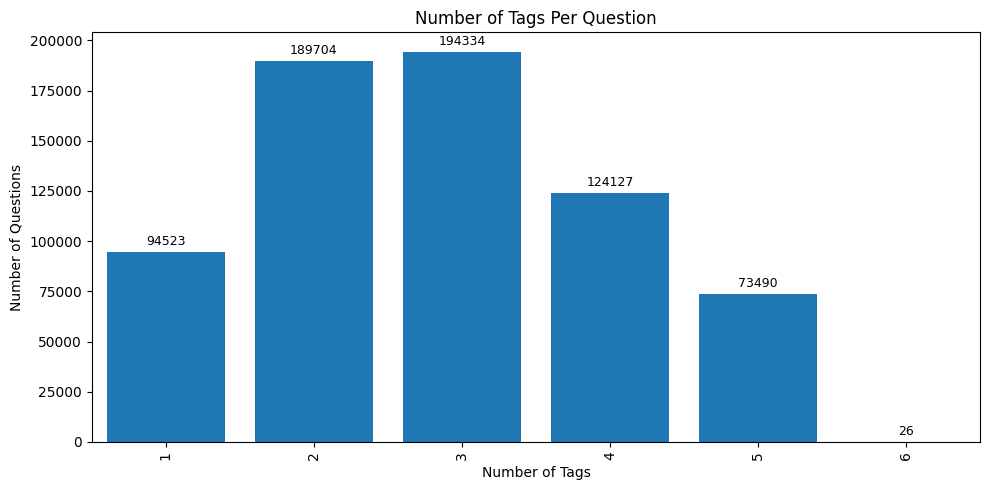

In [10]:
# Q1 Determine the Number of Tags Per Question 
import pandas as pd

posts_path = "/kaggle/working/Arjun_Assignment_data/dataset-20210607T020316Z-001/dataset/posts_short.csv"

posts = pd.read_csv(posts_path)

print("Dataset shape:", posts.shape)
display(posts.head())

questions = posts[posts["post_type_id"] == 1].copy()
print("Total questions:", len(questions))
questions["tag_count"] = (
    questions["tags"]
    .fillna("")
    .str.count(r"<[^>]+>")
)

display(questions[["id", "tags", "tag_count"]].head(10))

import matplotlib.pyplot as plt

tag_distribution = questions["tag_count"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
tag_distribution.plot(kind="bar")
bars = plt.bar(
    tag_distribution.index.astype(str),
    tag_distribution.values
)
plt.title("Number of Tags Per Question")
plt.xlabel("Number of Tags")
plt.ylabel("Number of Questions")
plt.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

In [11]:
print(posts["post_type_id"].value_counts(dropna=False))

post_type_id
1    676204
Name: count, dtype: int64


In [12]:
# Q2 Determine the Total Number of Unique Tags 
import re

all_tags = set()

for tag_string in questions["tags"].dropna():
    tags = re.findall(r"<([^>]+)>", tag_string)
    all_tags.update(tags)

print("Total number of unique tags:", len(all_tags))

Total number of unique tags: 25310


,Tag,Frequency
0,java,94846
1,javascript,81346
2,php,65333
3,c#,61899
4,python,61505
5,c++,40158
6,android,39910
7,html,33736
8,jquery,32601
9,mysql,24765


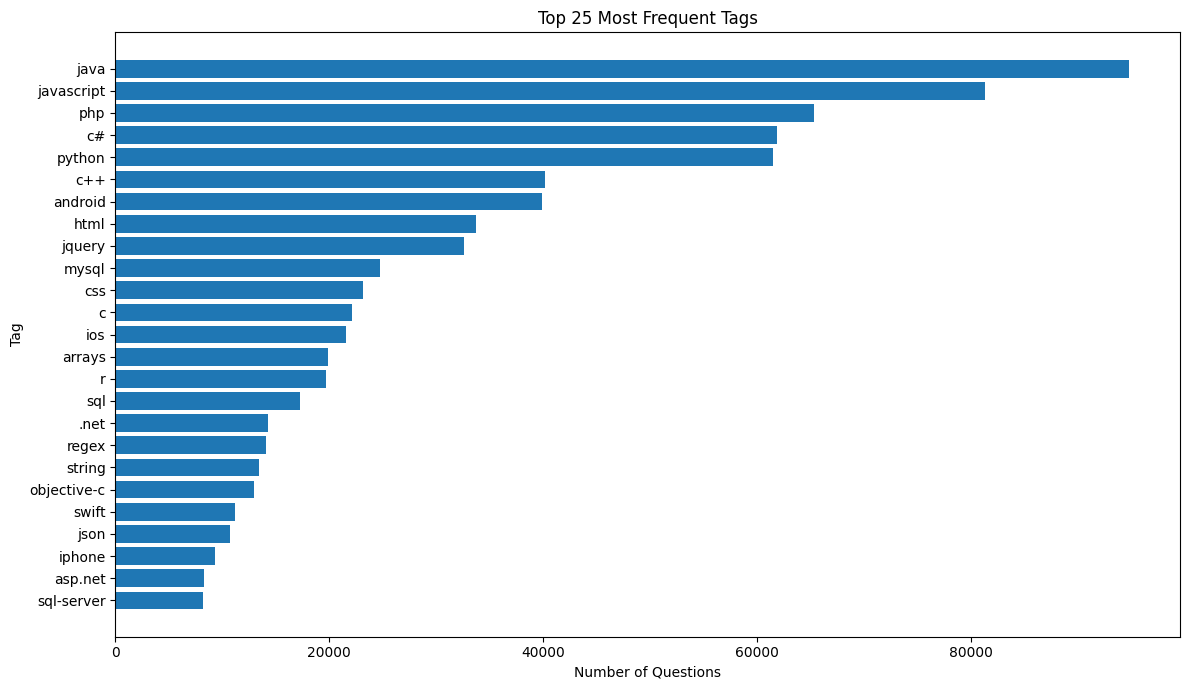

In [13]:
# Q3 Determine the top-25 Tags appearing frequently
import re
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

tag_counter = Counter()

for tag_string in questions["tags"].dropna():
    tag_counter.update(re.findall(r"<([^>]+)>", tag_string))

top_25_df = pd.DataFrame(
    tag_counter.most_common(25),
    columns=["Tag", "Frequency"]
)

display(top_25_df)

plt.figure(figsize=(12, 7))

plt.barh(
    top_25_df["Tag"][::-1],
    top_25_df["Frequency"][::-1]
)

plt.title("Top 25 Most Frequent Tags")
plt.xlabel("Number of Questions")
plt.ylabel("Tag")
plt.tight_layout()
plt.show()

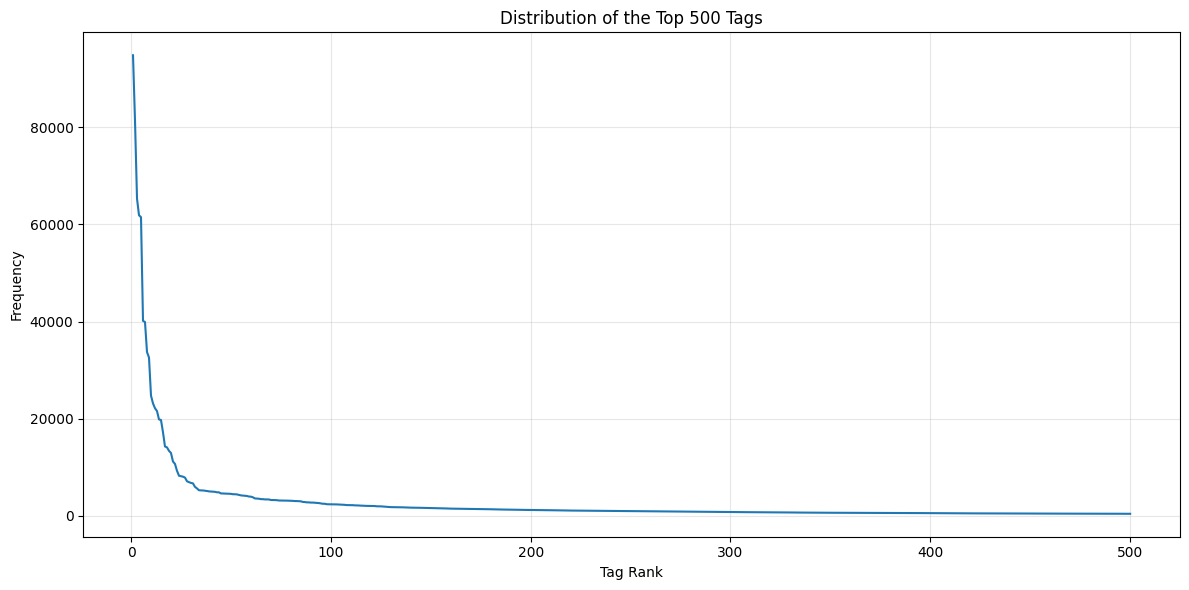

In [14]:
#Q4 Determine the nature of the distribution of top-500 tags
import matplotlib.pyplot as plt
import numpy as np

top_500 = tag_counter.most_common(500)

top_500_df = pd.DataFrame(
    top_500,
    columns=["Tag", "Frequency"]
)

# Frequency distribution by rank
plt.figure(figsize=(12, 6))
plt.plot(
    range(1, 501),
    top_500_df["Frequency"],
    linewidth=1.5
)

plt.title("Distribution of the Top 500 Tags")
plt.xlabel("Tag Rank")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Posts: (676204, 3)
Post links: (5292624, 3)
Total duplicate links: 682329
        post_id  related_post_id  link_type_id
872126    70714           355934             3
872127    86947            73713             3
872128    97679            85122             3
872129    99408             1711             3
872130    26925             8127             3


,total_questions,duplicate_questions,duplicate_ratio,duplicate_percentage
month,,,,
2008-07,4,0,0.000000,0.000000
2008-08,816,30,0.036765,3.676471
2008-09,2399,120,0.050021,5.002084
2008-10,2111,117,0.055424,5.542397
2008-11,1581,118,0.074636,7.463631
2008-12,1397,112,0.080172,8.017180
2009-01,1746,156,0.089347,8.934708
2009-02,1809,169,0.093422,9.342178
2009-03,1899,210,0.110585,11.058452


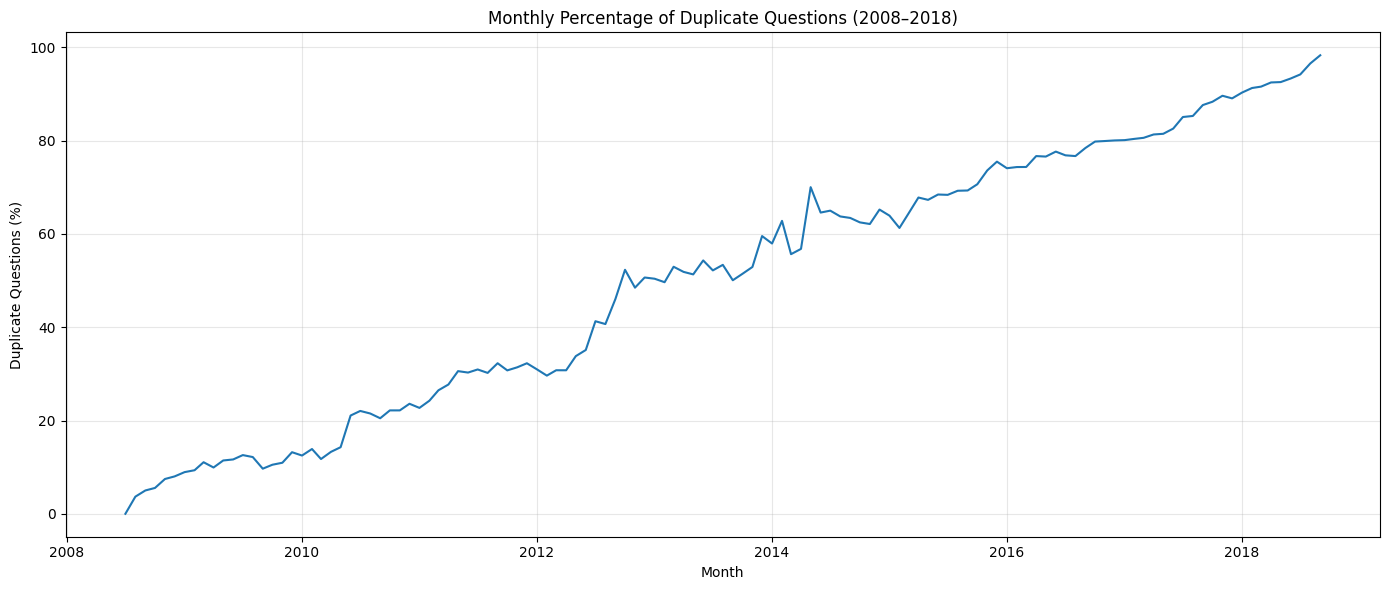

In [15]:
#Q5 Determine the ratio of duplicate questions asked in each month 
# use posts_short.csv for question dates and postLinks.csv to identify duplicate relationships.
 
import pandas as pd
import os

base_path = "/kaggle/working/Arjun_Assignment_data"

def find_file(filename):
    for root, dirs, files in os.walk(base_path):
        if filename in files:
            return os.path.join(root, filename)
    raise FileNotFoundError(filename)

posts_path = find_file("posts_short.csv")
links_path = find_file("postLinks.csv")

posts = pd.read_csv(
    posts_path,
    usecols=["id", "post_type_id", "creation_date"]
)

links = pd.read_csv(
    links_path,
    usecols=["post_id", "related_post_id", "link_type_id"]
)

print("Posts:", posts.shape)
print("Post links:", links.shape)


duplicate_links = links[links["link_type_id"] == 3].copy()
print("Total duplicate links:", len(duplicate_links))
print(duplicate_links.head())


# Keep questions only
questions = posts[posts["post_type_id"] == 1].copy()

# Convert dates
questions["creation_date"] = pd.to_datetime(
    questions["creation_date"],
    errors="coerce"
)

# Restrict to 2008–2018
questions = questions[
    questions["creation_date"].dt.year.between(2008, 2018)
].copy()

# Distinct question IDs identified as duplicates
duplicate_ids = set(duplicate_links["post_id"].dropna())

questions["is_duplicate"] = questions["id"].isin(duplicate_ids)

# Group by month
questions["month"] = (
    questions["creation_date"].dt.to_period("M")
)

monthly = questions.groupby("month").agg(
    total_questions=("id", "nunique"),
    duplicate_questions=("is_duplicate", "sum")
)

monthly["duplicate_ratio"] = (
    monthly["duplicate_questions"] / monthly["total_questions"]
)

monthly["duplicate_percentage"] = (
    monthly["duplicate_ratio"] * 100
)

display(monthly.head(12))


import matplotlib.pyplot as plt

monthly.index = monthly.index.to_timestamp()

plt.figure(figsize=(14, 6))

plt.plot(
    monthly.index,
    monthly["duplicate_percentage"],
    linewidth=1.5
)

plt.title("Monthly Percentage of Duplicate Questions (2008–2018)")
plt.xlabel("Month")
plt.ylabel("Duplicate Questions (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# # Number of unique questions and duplicate IDs
# print("Unique question IDs:", questions["id"].nunique())
# print("Unique duplicate post IDs:", len(duplicate_ids))

# # How many duplicate IDs actually exist in the questions dataset?
# question_ids = set(questions["id"].dropna())
# matched_duplicates = duplicate_ids.intersection(question_ids)

# print("Duplicate IDs matched to questions:", len(matched_duplicates))
# print(
#     "Matched duplicate percentage:",
#     round(len(matched_duplicates) / len(question_ids) * 100, 2),
#     "%"
# )

# # Inspect the latest months
# display(monthly.tail(12))

Unique question IDs: 676204
Unique duplicate post IDs: 631227
Duplicate IDs matched to questions: 399974
Matched duplicate percentage: 59.15 %


,total_questions,duplicate_questions,duplicate_ratio,duplicate_percentage
month,,,,
2017-10-01,8477,7490,0.883567,88.356730
2017-11-01,8765,7857,0.896406,89.640616
2017-12-01,7206,6419,0.890785,89.078546
2018-01-01,8166,7376,0.903257,90.325741
2018-02-01,7473,6823,0.913020,91.302021
2018-03-01,8320,7621,0.915986,91.598558
2018-04-01,7980,7381,0.924937,92.493734
2018-05-01,8172,7565,0.925722,92.572198
2018-06-01,7280,6795,0.933379,93.337912


In [17]:
# # Count duplicate question IDs that match the question dataset
# duplicate_ids = set(
#     duplicate_links["post_id"].dropna()
# )

# questions["is_duplicate"] = questions["id"].isin(
#     duplicate_ids
# )

# # Show the latest months
# recent = questions.copy()

# recent["month"] = (
#     recent["creation_date"].dt.to_period("M")
# )

# recent_monthly = recent.groupby("month").agg(
#     total_questions=("id", "nunique"),
#     duplicate_questions=("is_duplicate", "sum")
# )

# recent_monthly["percentage"] = (
#     recent_monthly["duplicate_questions"]
#     / recent_monthly["total_questions"] * 100
# )

# # display(recent_monthly.tail(12))

,total_questions,duplicate_questions,percentage
month,,,
2017-10,8477,7490,88.356730
2017-11,8765,7857,89.640616
2017-12,7206,6419,89.078546
2018-01,8166,7376,90.325741
2018-02,7473,6823,91.302021
2018-03,8320,7621,91.598558
2018-04,7980,7381,92.493734
2018-05,8172,7565,92.572198
2018-06,7280,6795,93.337912


In [18]:
# # Check the date coverage of the question dataset
# print("Earliest question:", questions["creation_date"].min())
# print("Latest question:", questions["creation_date"].max())

# # Check duplicate IDs against question IDs
# question_ids = set(questions["id"].dropna())
# duplicate_ids = set(duplicate_links["post_id"].dropna())

# print("Unique question IDs:", len(question_ids))
# print("Unique duplicate source IDs:", len(duplicate_ids))
# print("Matched duplicate source IDs:",
#       len(question_ids.intersection(duplicate_ids)))

# # Check duplicate links with both endpoints in the dataset
# related_ids = set(duplicate_links["related_post_id"].dropna())

# print("Duplicate links:", len(duplicate_links))
# print("Source IDs found in questions:",
#       len(duplicate_ids.intersection(question_ids)))
# print("Related IDs found in questions:",
#       len(related_ids.intersection(question_ids)))

Earliest question: 2008-07-31 21:42:52.667000
Latest question: 2018-09-02 05:02:16.480000
Unique question IDs: 676204
Unique duplicate source IDs: 631227
Matched duplicate source IDs: 399974
Duplicate links: 682329
Source IDs found in questions: 399974
Related IDs found in questions: 289294


In [19]:
# import pandas as pd

# # Recreate the question ID lookup
# question_lookup = questions[
#     ["id", "creation_date"]
# ].drop_duplicates("id")

# # Duplicate source IDs matched to question records
# matched = duplicate_links.merge(
#     question_lookup,
#     left_on="post_id",
#     right_on="id",
#     how="inner"
# )

# print("Matched duplicate-link rows:", len(matched))

# print("\nQuestion creation dates:")
# print(matched["creation_date"].describe())

# print("\nSample matched records:")
# display(
#     matched[
#         ["post_id", "related_post_id", "creation_date"]
#     ].head(10)
# )

Matched duplicate-link rows: 431153

Question creation dates:
count                           431153
mean     2015-08-31 13:23:22.549343488
min         2008-08-04 14:56:57.490000
25%      2014-01-16 13:14:35.329999872
50%         2016-01-24 22:03:14.040000
75%      2017-08-07 09:24:15.247000064
max         2018-09-02 05:02:16.480000
Name: creation_date, dtype: object

Sample matched records:


,post_id,related_post_id,creation_date
0,86947,73713,2008-09-17 19:53:03.700
1,26925,8127,2008-08-25 21:17:58.493
2,81150,48935,2008-09-17 08:32:48.360
3,110362,1854,2008-09-21 06:01:06.153
4,117348,506368,2008-09-22 20:20:39.560
5,2366,44965,2008-08-05 14:16:02.720
6,100322,21288,2008-09-19 07:48:16.360
7,100358,56107,2008-09-19 07:57:14.513
8,110804,1586658,2008-09-21 11:27:44.967
9,142242,211329,2008-09-26 21:58:42.167


,total_questions,duplicate_questions,duplicate_percentage
month,,,
2008-07,4,0,0.000000
2008-08,816,30,3.676471
2008-09,2399,120,5.002084
2008-10,2111,117,5.542397
2008-11,1581,118,7.463631
2008-12,1397,112,8.017180
2009-01,1746,156,8.934708
2009-02,1809,169,9.342178
2009-03,1899,210,11.058452


,total_questions,duplicate_questions,duplicate_percentage
month,,,
2017-10,8477,7490,88.356730
2017-11,8765,7857,89.640616
2017-12,7206,6419,89.078546
2018-01,8166,7376,90.325741
2018-02,7473,6823,91.302021
2018-03,8320,7621,91.598558
2018-04,7980,7381,92.493734
2018-05,8172,7565,92.572198
2018-06,7280,6795,93.337912


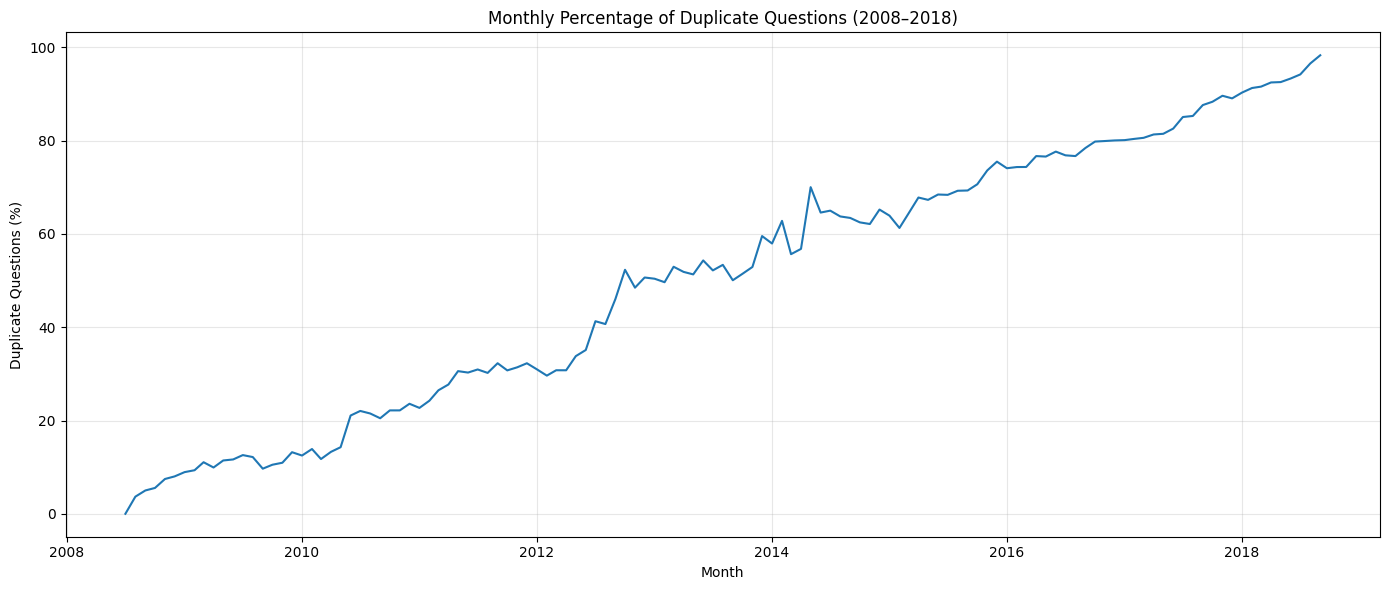

In [20]:
# import pandas as pd
# import matplotlib.pyplot as plt

# # Keep questions only
# questions = posts.loc[
#     posts["post_type_id"] == 1,
#     ["id", "creation_date"]
# ].copy()

# questions["creation_date"] = pd.to_datetime(
#     questions["creation_date"], errors="coerce"
# )

# # Keep the requested period
# questions = questions[
#     questions["creation_date"].dt.year.between(2008, 2018)
# ].copy()

# # Identify duplicate source question IDs
# duplicate_ids = set(
#     links.loc[
#         links["link_type_id"] == 3,
#         "post_id"
#     ].dropna()
# )

# # Count each question only once
# questions["is_duplicate"] = questions["id"].isin(duplicate_ids)
# questions["month"] = questions["creation_date"].dt.to_period("M")

# monthly = questions.groupby("month").agg(
#     total_questions=("id", "nunique"),
#     duplicate_questions=("is_duplicate", "sum")
# )

# monthly["duplicate_percentage"] = (
#     monthly["duplicate_questions"]
#     / monthly["total_questions"] * 100
# )

# display(monthly.head(12))
# display(monthly.tail(12))


# plt.figure(figsize=(14, 6))

# plt.plot(
#     monthly.index.to_timestamp(),
#     monthly["duplicate_percentage"],
#     linewidth=1.5
# )

# plt.title("Monthly Percentage of Duplicate Questions (2008–2018)")
# plt.xlabel("Month")
# plt.ylabel("Duplicate Questions (%)")
# plt.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.show()

In [21]:
# # Match duplicate links to the creation dates of both posts
# question_dates = posts.set_index("id")["creation_date"]

# duplicate_links = links[links["link_type_id"] == 3].copy()

# duplicate_links["post_date"] = pd.to_datetime(
#     duplicate_links["post_id"].map(question_dates),
#     errors="coerce"
# )

# duplicate_links["related_date"] = pd.to_datetime(
#     duplicate_links["related_post_id"].map(question_dates),
#     errors="coerce"
# )

# matched_dates = duplicate_links.dropna(
#     subset=["post_date", "related_date"]
# )

# print("Matched links:", len(matched_dates))

# print(
#     "Duplicate post created after related post:",
#     (matched_dates["post_date"] > matched_dates["related_date"]).mean()
# )

# print(
#     "Duplicate post created before related post:",
#     (matched_dates["post_date"] < matched_dates["related_date"]).mean()
# )

Matched links: 429542
Duplicate post created after related post: 0.975986050258182
Duplicate post created before related post: 0.024002309436562664


In [22]:
# # Number of questions and duplicate questions per year
# yearly = questions.groupby(
#     questions["creation_date"].dt.year
# ).agg(
#     total_questions=("id", "nunique"),
#     duplicate_questions=("is_duplicate", "sum")
# )

# yearly["duplicate_percentage"] = (
#     yearly["duplicate_questions"]
#     / yearly["total_questions"] * 100
# )

# display(yearly.round(2))

,total_questions,duplicate_questions,duplicate_percentage
creation_date,,,
2008,8308,497,5.98
2009,26141,2893,11.07
2010,39683,7364,18.56
2011,58404,17059,29.21
2012,69149,27764,40.15
2013,82366,43243,52.50
2014,76322,47768,62.59
2015,79091,54266,68.61
2016,85194,65651,77.06


In [23]:
# duplicate_ids = set(
#     links.loc[links["link_type_id"] == 3, "post_id"].dropna()
# )

# question_ids = set(questions["id"].dropna())

# print("Unique duplicate IDs:", len(duplicate_ids))
# print("Duplicate IDs found in questions:", len(duplicate_ids & question_ids))
# print("Total questions:", len(question_ids))
# print(
#     "Matched duplicate IDs (%):",
#     round(len(duplicate_ids & question_ids) / len(question_ids) * 100, 2)
# )

Unique duplicate IDs: 631227
Duplicate IDs found in questions: 399974
Total questions: 676204
Matched duplicate IDs (%): 59.15


In [24]:
# # Check duplicate-link coverage by year
# duplicate_links = links[links["link_type_id"] == 3].copy()

# question_dates = posts.set_index("id")["creation_date"]

# duplicate_links["duplicate_date"] = pd.to_datetime(
#     duplicate_links["post_id"].map(question_dates),
#     errors="coerce"
# )

# duplicate_links["duplicate_year"] = (
#     duplicate_links["duplicate_date"].dt.year
# )

# print("Total questions in posts:", posts["id"].nunique())
# print("Total duplicate-link records:", len(duplicate_links))
# print("Unique IDs in duplicate links:", duplicate_links["post_id"].nunique())

# print("\nDuplicate-link records by year:")
# display(
#     duplicate_links.groupby("duplicate_year")
#     .agg(
#         link_records=("post_id", "size"),
#         unique_duplicate_questions=("post_id", "nunique")
#     )
# )

Total questions in posts: 676204
Total duplicate-link records: 682329
Unique IDs in duplicate links: 631227

Duplicate-link records by year:


,link_records,unique_duplicate_questions
duplicate_year,,
2008.0,527,497
2009.0,3167,2893
2010.0,7908,7364
2011.0,18213,17059
2012.0,29642,27764
2013.0,46199,43243
2014.0,50044,47768
2015.0,55776,54266
2016.0,67631,65651


In [25]:
# # IDs of all questions in posts_short.csv
# question_ids = set(posts["id"].dropna())

# # Unique IDs marked as duplicates in postLinks
# duplicate_ids = set(
#     links.loc[
#         links["link_type_id"] == 3, "post_id"
#     ].dropna()
# )

# matched_ids = duplicate_ids & question_ids
# unmatched_ids = duplicate_ids - question_ids

# print("Unique duplicate IDs:", len(duplicate_ids))
# print("Matched duplicate IDs:", len(matched_ids))
# print("Unmatched duplicate IDs:", len(unmatched_ids))
# print(
#     "Percentage unmatched:",
#     round(len(unmatched_ids) / len(duplicate_ids) * 100, 2),
#     "%"
# )

# # Look at duplicate IDs that are absent from posts_short.csv
# unmatched_links = links[
#     (links["link_type_id"] == 3)
#     & (~links["post_id"].isin(question_ids))
# ].copy()

# print("Unmatched duplicate-link records:", len(unmatched_links))
# print("Sample unmatched IDs:")
# display(unmatched_links.head(10))

Unique duplicate IDs: 631227
Matched duplicate IDs: 399974
Unmatched duplicate IDs: 231253
Percentage unmatched: 36.64 %
Unmatched duplicate-link records: 251176
Sample unmatched IDs:


,post_id,related_post_id,link_type_id
872126,70714,355934,3
872128,97679,85122,3
872129,99408,1711,3
872131,73185,672,3
872136,87657,24692,3
872137,99425,1711,3
872138,104203,10688,3
872139,107122,3830,3
872140,107122,111761,3
872141,83803,19207,3


In [26]:
# import pandas as pd

# posts_long_path = (
#     "/kaggle/working/Arjun_Assignment_data/"
#     "dataset-20210607T020316Z-001/dataset/posts_long.csv"
# )

# # Load only the columns needed for the check
# posts_long_ids = pd.read_csv(
#     posts_long_path,
#     usecols=["id", "creation_date"]
# )

# long_ids = set(posts_long_ids["id"].dropna())

# print("Questions in posts_long:", len(long_ids))
# print("Missing duplicate IDs found in posts_long:", len(unmatched_ids & long_ids))
# print("Missing duplicate IDs still absent:", len(unmatched_ids - long_ids))

Questions in posts_long: 676204
Missing duplicate IDs found in posts_long: 0
Missing duplicate IDs still absent: 231253


In [27]:
# print("posts_short ID range:")
# print(posts["id"].min(), "to", posts["id"].max())

# print("\nposts_long ID range:")
# print(posts_long_ids["id"].min(), "to", posts_long_ids["id"].max())

# print("\npostLinks duplicate ID range:")
# print(
#     links.loc[links["link_type_id"] == 3, "post_id"].min(),
#     "to",
#     links.loc[links["link_type_id"] == 3, "post_id"].max()
# )

# print("\nQuestion date range:")
# print(posts["creation_date"].min(), "to", posts["creation_date"].max())

posts_short ID range:
4 to 52134121

posts_long ID range:
4 to 52134121

postLinks duplicate ID range:
559 to 52135030

Question date range:
2008-07-31T21:42:52.667 to 2018-09-02T05:02:16.480


In [28]:
# duplicate_ids = set(
#     links.loc[links["link_type_id"] == 3, "post_id"].dropna()
# )

# question_ids = set(posts["id"].dropna())
# unmatched_ids = duplicate_ids - question_ids

# print("Unmatched IDs:", len(unmatched_ids))
# print("Unmatched IDs below minimum question ID:",
#       sum(x < posts["id"].min() for x in unmatched_ids))
# print("Unmatched IDs above maximum question ID:",
#       sum(x > posts["id"].max() for x in unmatched_ids))
# print("Unmatched IDs within question ID range:",
#       sum(posts["id"].min() <= x <= posts["id"].max()
#           for x in unmatched_ids))

Unmatched IDs: 231253
Unmatched IDs below minimum question ID: 0
Unmatched IDs above maximum question ID: 12
Unmatched IDs within question ID range: 231241


In [29]:
# duplicate_links = links[links["link_type_id"] == 3].copy()

# question_ids = set(posts["id"].dropna())

# duplicate_links["post_id_found"] = (
#     duplicate_links["post_id"].isin(question_ids)
# )

# duplicate_links["related_post_id_found"] = (
#     duplicate_links["related_post_id"].isin(question_ids)
# )

# print("Total duplicate-link records:", len(duplicate_links))

# print(
#     "Both questions found:",
#     (
#         duplicate_links["post_id_found"]
#         & duplicate_links["related_post_id_found"]
#     ).sum()
# )

# print(
#     "Duplicate question found, related question missing:",
#     (
#         duplicate_links["post_id_found"]
#         & ~duplicate_links["related_post_id_found"]
#     ).sum()
# )

# print(
#     "Duplicate question missing, related question found:",
#     (
#         ~duplicate_links["post_id_found"]
#         & duplicate_links["related_post_id_found"]
#     ).sum()
# )

# print(
#     "Both questions missing:",
#     (
#         ~duplicate_links["post_id_found"]
#         & ~duplicate_links["related_post_id_found"]
#     ).sum()
# )

Total duplicate-link records: 682329
Both questions found: 429542
Duplicate question found, related question missing: 1611
Duplicate question missing, related question found: 239655
Both questions missing: 11521


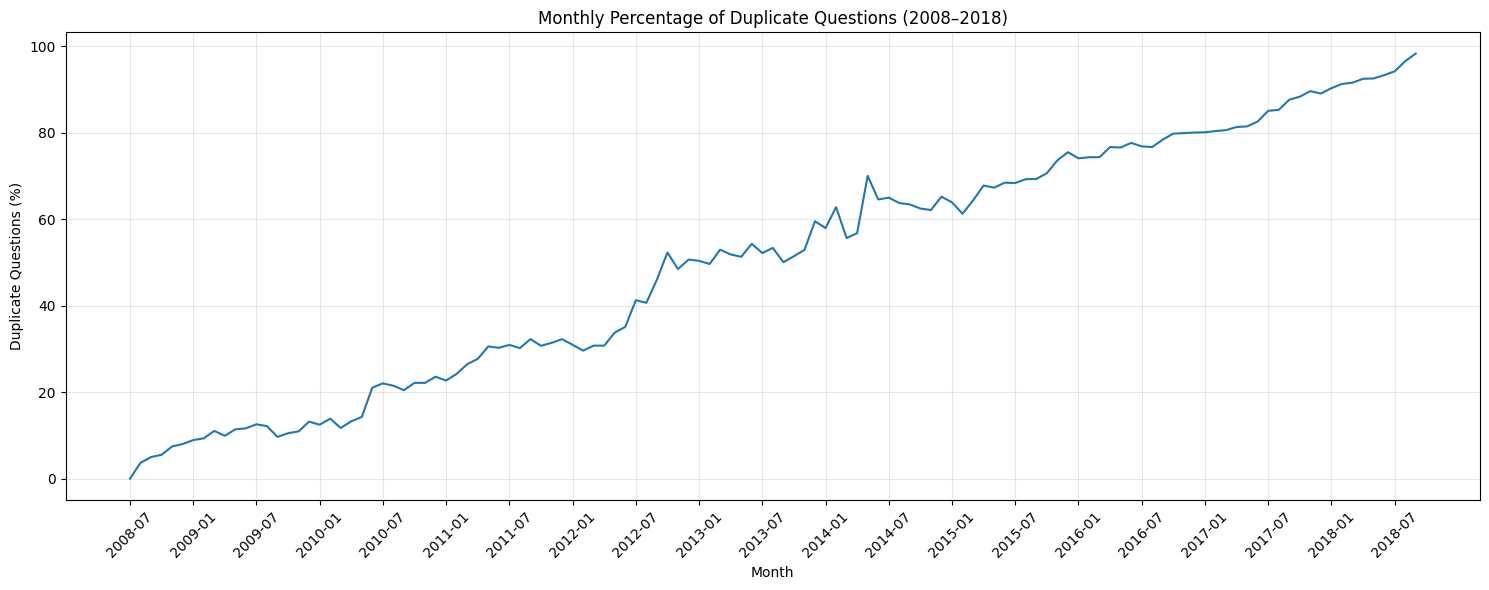

In [30]:
# import pandas as pd
# import matplotlib.pyplot as plt

# # All questions and their creation dates
# questions = posts[posts["post_type_id"] == 1].copy()

# questions["creation_date"] = pd.to_datetime(
#     questions["creation_date"], errors="coerce"
# )

# # Unique questions marked as duplicates
# duplicate_ids = set(
#     links.loc[
#         links["link_type_id"] == 3, "post_id"
#     ].dropna()
# )

# # Restrict to the study period
# questions = questions[
#     questions["creation_date"].dt.year.between(2008, 2018)
# ].copy()

# questions["is_duplicate"] = questions["id"].isin(duplicate_ids)
# questions["month"] = questions["creation_date"].dt.to_period("M")

# # Calculate monthly totals and percentages
# monthly = questions.groupby("month").agg(
#     total_questions=("id", "nunique"),
#     duplicate_questions=("is_duplicate", "sum")
# )

# monthly["duplicate_percentage"] = (
#     monthly["duplicate_questions"]
#     / monthly["total_questions"] * 100
# )

# # Plot the monthly trend
# plt.figure(figsize=(15, 6))
# plt.plot(
#     monthly.index.astype(str),
#     monthly["duplicate_percentage"],
#     linewidth=1.5
# )

# plt.title("Monthly Percentage of Duplicate Questions (2008–2018)")
# plt.xlabel("Month")
# plt.ylabel("Duplicate Questions (%)")
# plt.xticks(
#     range(0, len(monthly), 6),
#     monthly.index.astype(str)[::6],
#     rotation=45
# )
# plt.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.show()

Total questions: 676204
Total questions: 676204
Duplicate questions found: 399974


,tag,total_questions,duplicate_questions,duplicate_percentage
25299,ner,1,1,100.0
25300,3d-printing,1,1,100.0
25301,read-the-docs,1,1,100.0
25302,ant-media-server,1,1,100.0
25303,bucket-sort,1,1,100.0
25304,mirc,1,1,100.0
25305,codeanywhere,1,1,100.0
25306,iis-express-10,1,1,100.0
12884,browser-action,5,5,100.0
25276,django-rq,1,1,100.0


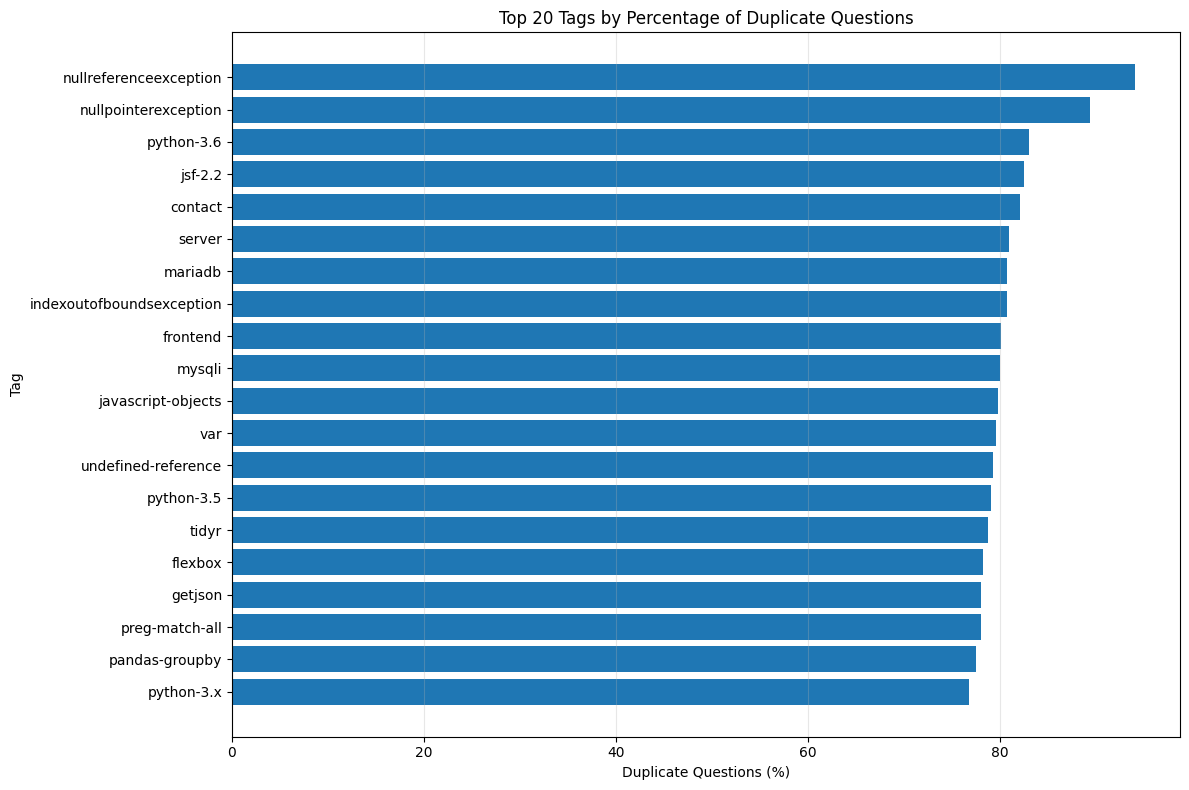

In [41]:
# question 6
# Determine the percentage of duplicate questions associated with different tags 
# Each Stack Overflow question has some tags associated with it which is an 
# identification of the topic of the question content. For each tag in your dataset, 
# determine the number of duplicate questions associated with the tag over the total 
# number of questions (calculate the percentage). Determine the top-20 tags based on 
# the previously calculated numbers and then show the percentage in a bar chart.Determine the percentage of duplicate questions associated with different tags 
# Each Stack Overflow question has some tags associated with it which is an 
# identification of the topic of the question content. For each tag in your dataset, 
# determine the number of duplicate questions associated with the tag over the total 
# number of questions (calculate the percentage). Determine the top-20 tags based on 
# the previously calculated numbers and then show the percentage in a bar chart.

import pandas as pd
import re
from collections import Counter
import matplotlib.pyplot as plt

posts_path = (
    "/kaggle/working/Arjun_Assignment_data/"
    "dataset-20210607T020316Z-001/dataset/posts_short.csv"
)

questions = pd.read_csv(
    posts_path,
    usecols=["id", "post_type_id", "tags"]
)

questions = questions[
    questions["post_type_id"] == 1
].copy()

print("Total questions:", questions["id"].nunique())
questions.head()

duplicate_ids = set(
    links.loc[
        links["link_type_id"] == 3,
        "post_id"
    ].dropna()
)

questions["is_duplicate"] = questions["id"].isin(
    duplicate_ids
)

print("Total questions:", questions["id"].nunique())
print(
    "Duplicate questions found:",
    questions.loc[questions["is_duplicate"], "id"].nunique()
)

tag_stats = Counter()
duplicate_tag_stats = Counter()

for _, row in questions.iterrows():
    tags = set(re.findall(r"<([^>]+)>", str(row["tags"])))

    for tag in tags:
        tag_stats[tag] += 1

        if row["is_duplicate"]:
            duplicate_tag_stats[tag] += 1

tag_results = pd.DataFrame({
    "tag": list(tag_stats.keys()),
    "total_questions": [
        tag_stats[tag] for tag in tag_stats
    ],
    "duplicate_questions": [
        duplicate_tag_stats[tag] for tag in tag_stats
    ]
})

tag_results["duplicate_percentage"] = (
    tag_results["duplicate_questions"]
    / tag_results["total_questions"] * 100
)

tag_results = tag_results.sort_values(
    "duplicate_percentage",
    ascending=False
)

display(tag_results.head(20))

top_20_tags = (
    tag_results[
        tag_results["total_questions"] >= 100
    ]
    .sort_values(
        "duplicate_percentage",
        ascending=False
    )
    .head(20)
    .sort_values("duplicate_percentage")
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_20_tags["tag"],
    top_20_tags["duplicate_percentage"]
)

plt.xlabel("Duplicate Questions (%)")
plt.ylabel("Tag")
plt.title("Top 20 Tags by Percentage of Duplicate Questions")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
reliable_tags = tag_results[
    tag_results["total_questions"] >= 100
]

top_20_tags = reliable_tags.sort_values(
    "duplicate_percentage",
    ascending=False
).head(20)

print(top_20_tags)

                             tag  total_questions  duplicate_questions  \
3622      nullreferenceexception              505                  475   
222         nullpointerexception             2373                 2122   
21303                 python-3.6              183                  152   
16216                    jsf-2.2              211                  174   
5494                     contact              106                   87   
6524                      server              342                  277   
8309                     mariadb              156                  126   
4280   indexoutofboundsexception              290                  234   
1833                    frontend              136                  109   
433                       mysqli             3050                 2439   
262           javascript-objects              356                  284   
903                          var              186                  148   
4263         undefined-reference      

Valid duplicate links: 431153


count    431153.000000
mean       2940.065468
std        8458.194047
min           0.001992
25%           0.209015
50%           1.957675
75%          58.200027
max       86959.576839
Name: time_to_close_hours, dtype: float64

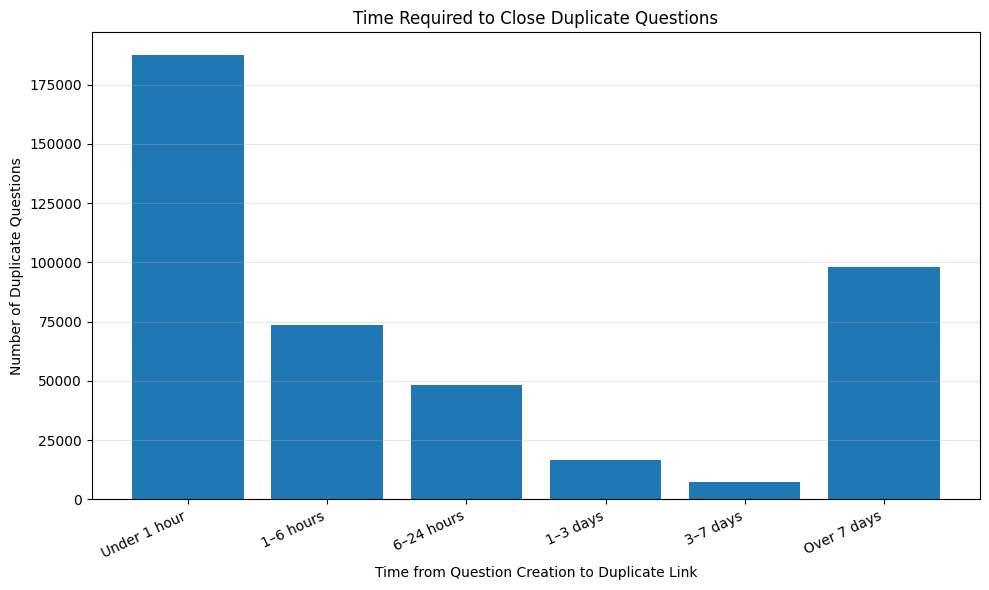

In [36]:
# Q7:Determine the time required to close duplicate questions 
# You need to generate a bar chart 
import pandas as pd
import matplotlib.pyplot as plt

posts_path = (
    "/kaggle/working/Arjun_Assignment_data/"
    "dataset-20210607T020316Z-001/dataset/posts_short.csv"
)

links_path = (
    "/kaggle/working/Arjun_Assignment_data/"
    "dataset-20210607T020316Z-001/dataset/postLinks.csv"
)

posts_dates = pd.read_csv(
    posts_path,
    usecols=["id", "creation_date"]
)

links = pd.read_csv(
    links_path,
    usecols=[
        "post_id",
        "related_post_id",
        "link_type_id",
        "creation_date"
    ]
)

posts_dates["creation_date"] = pd.to_datetime(
    posts_dates["creation_date"], errors="coerce"
)

links["creation_date"] = pd.to_datetime(
    links["creation_date"], errors="coerce"
)


duplicate_links = links[
    links["link_type_id"] == 3
].copy()

# Get the creation date of the duplicate question
duplicate_links = duplicate_links.merge(
    posts_dates[["id", "creation_date"]].rename(
        columns={
            "id": "post_id",
            "creation_date": "question_creation_date"
        }
    ),
    on="post_id",
    how="inner"
)

# Calculate time between question creation and duplicate-link creation
duplicate_links["time_to_close_hours"] = (
    duplicate_links["creation_date"]
    - duplicate_links["question_creation_date"]
).dt.total_seconds() / 3600

# Remove invalid or negative durations
duplicate_links = duplicate_links[
    duplicate_links["time_to_close_hours"].notna()
    & (duplicate_links["time_to_close_hours"] >= 0)
].copy()

print("Valid duplicate links:", len(duplicate_links))
display(duplicate_links["time_to_close_hours"].describe())


bins = [-0.001, 1, 6, 24, 72, 168, float("inf")]

labels = [
    "Under 1 hour",
    "1–6 hours",
    "6–24 hours",
    "1–3 days",
    "3–7 days",
    "Over 7 days"
]

duplicate_links["time_category"] = pd.cut(
    duplicate_links["time_to_close_hours"],
    bins=bins,
    labels=labels
)

time_counts = (
    duplicate_links["time_category"]
    .value_counts(sort=False)
)

plt.figure(figsize=(10, 6))
plt.bar(time_counts.index.astype(str), time_counts.values)

plt.title("Time Required to Close Duplicate Questions")
plt.xlabel("Time from Question Creation to Duplicate Link")
plt.ylabel("Number of Duplicate Questions")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Questions: 676204
Users: 9321924


,id,reputation
0,-1,1
1,1,44300
2,2,3491
3,3,13418
4,4,28768


Duplicate questions found: 399974
Duplicate questions with a known owner: 399974
Matched duplicate-question records: 393539
Unique users: 284611


,owner_user_id,reputation
0,121,10810
1,402,12865
2,91,113539
3,56,8780
4,799,3279


,number_of_questions
reputation_category,
1–100,191951
"101–1,000",109827
"1,001–5,000",60556
"5,001–10,000",15244
"10,001–50,000",13827
"Above 50,000",2134


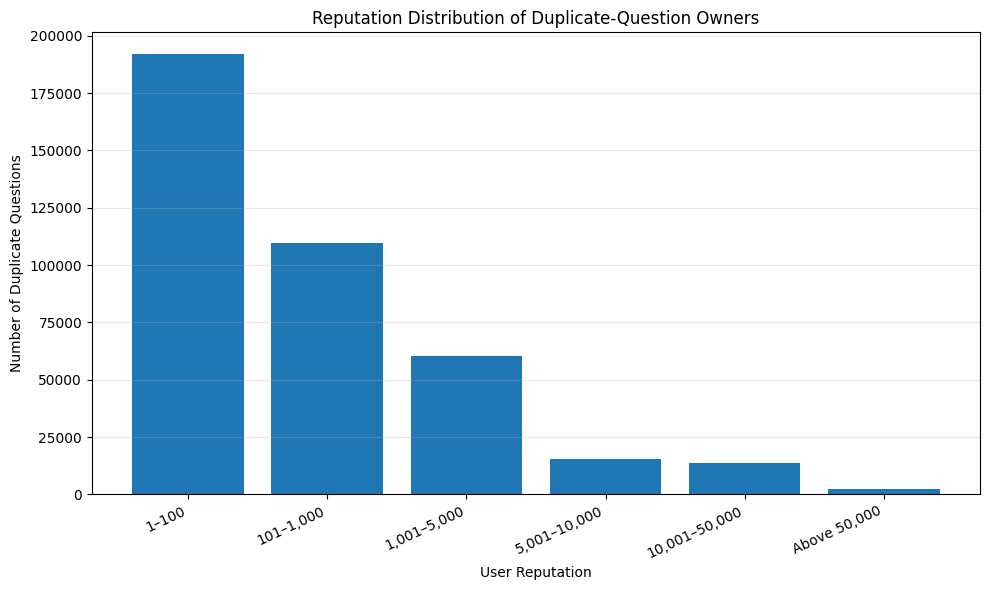

In [37]:
# Q8: Distribution of the reputation of users whose questions are closed as 
# duplicates 
# The goal of this analysis is to verify whether duplicated questions are only asked by 
# low-reputation users or not. If that is the case, we need to educate novice or low
# reputation users to avoid creating duplicate questions. You can generate a bar 
# chart to show the number of users for different reputation categories. Use your 
# own judgement to answer the question properly (e.g., break the reputation into 
# different ranges). 
import pandas as pd
import matplotlib.pyplot as plt

base_path = (
    "/kaggle/working/Arjun_Assignment_data/"
    "dataset-20210607T020316Z-001/dataset/"
)

users_path = (
    "/kaggle/working/Arjun_Assignment_data/"
    "dataset-20210607T020316Z-002/dataset/users.csv"
)

# Load question IDs and their owners
posts = pd.read_csv(
    base_path + "posts_short.csv",
    usecols=["id", "post_type_id", "owner_user_id"]
)

# Load user IDs and reputation
users = pd.read_csv(
    users_path,
    usecols=["id", "reputation"]
)

print("Questions:", len(posts))
print("Users:", len(users))

display(users.head())


duplicate_ids = set(
    links.loc[
        links["link_type_id"] == 3,
        "post_id"
    ].dropna()
)

duplicate_questions = posts[
    (posts["post_type_id"] == 1)
    & (posts["id"].isin(duplicate_ids))
].copy()

print(
    "Duplicate questions found:",
    duplicate_questions["id"].nunique()
)

print(
    "Duplicate questions with a known owner:",
    duplicate_questions["owner_user_id"].notna().sum()
)


# Remove questions without a recorded owner
duplicate_questions = duplicate_questions.dropna(
    subset=["owner_user_id"]
).copy()

# Match owner IDs to user IDs
duplicate_questions["owner_user_id"] = (
    duplicate_questions["owner_user_id"].astype("int64")
)

users["id"] = users["id"].astype("int64")

duplicate_users = duplicate_questions.merge(
    users,
    left_on="owner_user_id",
    right_on="id",
    how="inner"
)

print("Matched duplicate-question records:", len(duplicate_users))
print("Unique users:", duplicate_users["owner_user_id"].nunique())

display(duplicate_users[["owner_user_id", "reputation"]].head())


bins = [0, 100, 1000, 5000, 10000, 50000, float("inf")]

labels = [
    "1–100",
    "101–1,000",
    "1,001–5,000",
    "5,001–10,000",
    "10,001–50,000",
    "Above 50,000"
]

duplicate_users["reputation_category"] = pd.cut(
    duplicate_users["reputation"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

reputation_counts = (
    duplicate_users["reputation_category"]
    .value_counts(sort=False)
)

display(reputation_counts.rename("number_of_questions").to_frame())

plt.figure(figsize=(10, 6))

plt.bar(
    reputation_counts.index.astype(str),
    reputation_counts.values
)

plt.title("Reputation Distribution of Duplicate-Question Owners")
plt.xlabel("User Reputation")
plt.ylabel("Number of Duplicate Questions")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Number of top tags: 500
First 10 tags: [('java', 94846), ('javascript', 81346), ('php', 65333), ('c#', 61899), ('python', 61505), ('c++', 40158), ('android', 39910), ('html', 33736), ('jquery', 32601), ('mysql', 24765)]
Total questions: 676204
Questions covered by top 500 tags: 662549
Coverage percentage: 97.98%


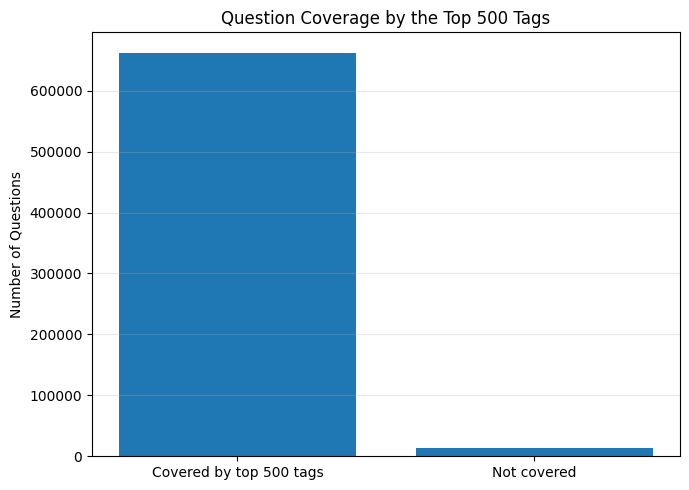

In [38]:
# Q9: Consider the first 500 tags and determine how many percentage of questions 
# are been covered 

import re
from collections import Counter

tag_frequency = Counter()

for tag_string in questions["tags"].dropna():
    tags = set(re.findall(r"<([^>]+)>", tag_string))
    tag_frequency.update(tags)

top_500_tags = {
    tag for tag, count in tag_frequency.most_common(500)
}

print("Number of top tags:", len(top_500_tags))
print("First 10 tags:", list(tag_frequency.most_common(10)))



def has_top_tag(tag_string, top_tags):
    tags = set(re.findall(r"<([^>]+)>", str(tag_string)))
    return bool(tags & top_tags)

questions["has_top_500_tag"] = questions["tags"].apply(
    lambda x: has_top_tag(x, top_500_tags)
)

total_questions = questions["id"].nunique()

covered_questions = questions.loc[
    questions["has_top_500_tag"], "id"
].nunique()

coverage_percentage = covered_questions / total_questions * 100

print("Total questions:", total_questions)
print("Questions covered by top 500 tags:", covered_questions)
print(f"Coverage percentage: {coverage_percentage:.2f}%")


import matplotlib.pyplot as plt

not_covered = total_questions - covered_questions

plt.figure(figsize=(7, 5))
plt.bar(
    ["Covered by top 500 tags", "Not covered"],
    [covered_questions, not_covered]
)

plt.title("Question Coverage by the Top 500 Tags")
plt.ylabel("Number of Questions")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Number of top tags: 5000
Total questions: 676204
Questions covered: 675145
Questions not covered: 1059
Coverage percentage: 99.84%


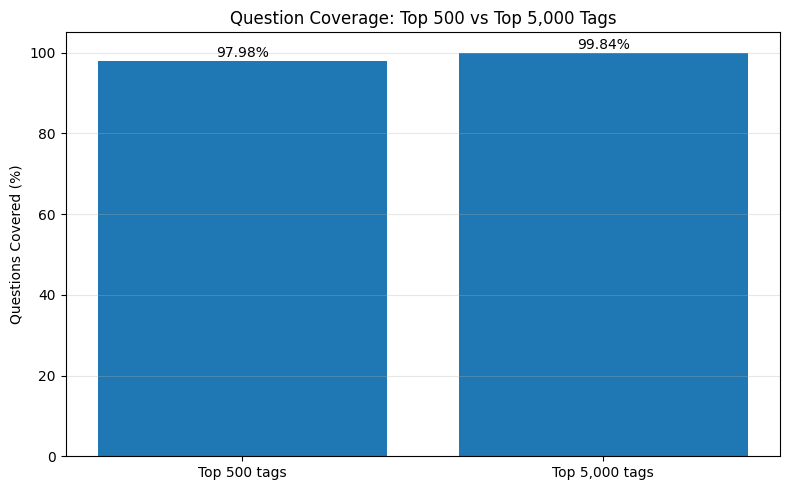

In [40]:
# Q10: Find the 5,000 most frequent tags
top_5000_tags = {
    tag for tag, count in tag_frequency.most_common(5000)
}

print("Number of top tags:", len(top_5000_tags))

# Count questions containing at least one of these tags
questions["has_top_5000_tag"] = questions["tags"].apply(
    lambda x: has_top_tag(x, top_5000_tags)
)

covered_5000 = questions.loc[
    questions["has_top_5000_tag"], "id"
].nunique()

total_questions = questions["id"].nunique()
not_covered_5000 = total_questions - covered_5000

coverage_5000 = covered_5000 / total_questions * 100

print("Total questions:", total_questions)
print("Questions covered:", covered_5000)
print("Questions not covered:", not_covered_5000)
print(f"Coverage percentage: {coverage_5000:.2f}%")


import matplotlib.pyplot as plt

coverage_values = [97.98, coverage_5000]
labels = ["Top 500 tags", "Top 5,000 tags"]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, coverage_values)

plt.ylabel("Questions Covered (%)")
plt.title("Question Coverage: Top 500 vs Top 5,000 Tags")
plt.ylim(0, 105)

for bar, value in zip(bars, coverage_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

java: 59498
javascript: 56178
php: 44619
python: 38427
c#: 35913
c++: 25037
html: 23282
android: 22987
jquery: 21293
mysql: 16641


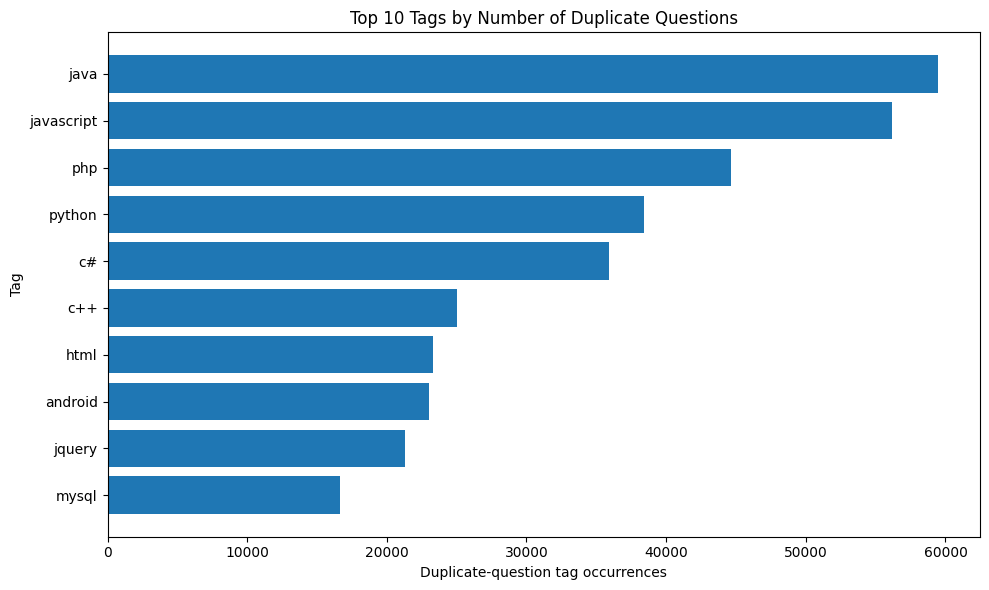

In [45]:
# question 11 Which 10 tags have the highest number of duplicate questions?
import re
from collections import Counter
import matplotlib.pyplot as plt

duplicate_tag_counts = Counter()

for _, row in questions.iterrows():
    if row["is_duplicate"]:
        tags = set(re.findall(r"<([^>]+)>", str(row["tags"])))
        duplicate_tag_counts.update(tags)

top_10_duplicate_tags = duplicate_tag_counts.most_common(10)

for tag, count in top_10_duplicate_tags:
    print(f"{tag}: {count}")

tags_df = pd.DataFrame(
    top_10_duplicate_tags,
    columns=["tag", "duplicate_questions"]
).sort_values("duplicate_questions")

plt.figure(figsize=(10, 6))
plt.barh(tags_df["tag"], tags_df["duplicate_questions"])
plt.title("Top 10 Tags by Number of Duplicate Questions")
plt.xlabel("Duplicate-question tag occurrences")
plt.ylabel("Tag")
plt.tight_layout()
plt.show()

,duplicate_questions
year,
2008,497
2009,2893
2010,7364
2011,17059
2012,27764
2013,43243
2014,47768
2015,54266
2016,65651


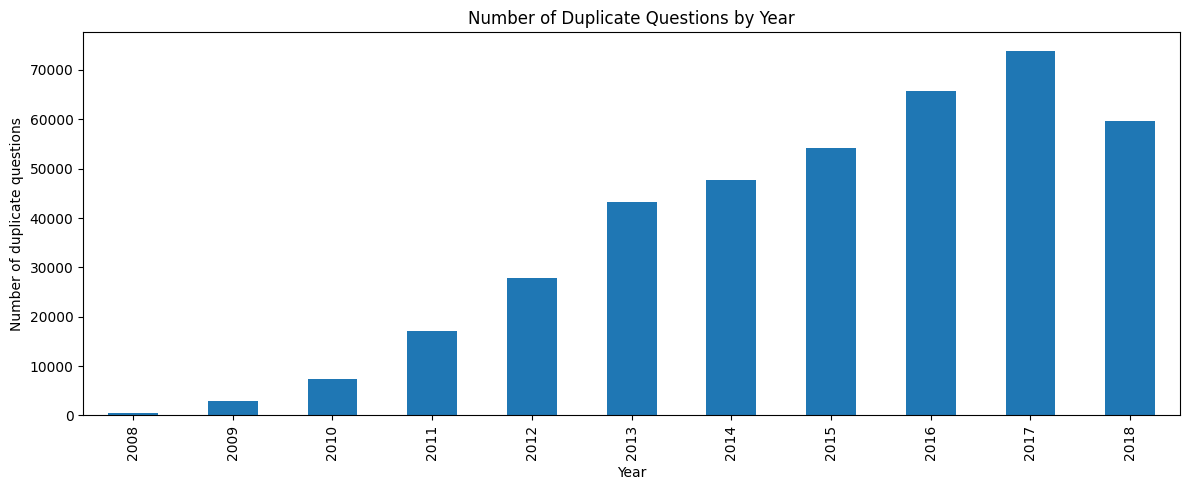

In [46]:
# Q12. Which years had the highest number of duplicate questions?
# Load question creation dates
posts_dates = pd.read_csv(
    posts_path,
    usecols=["id", "post_type_id", "creation_date"]
)

posts_dates["creation_date"] = pd.to_datetime(
    posts_dates["creation_date"], errors="coerce"
)

duplicate_ids = set(
    links.loc[links["link_type_id"] == 3, "post_id"].dropna()
)

yearly_duplicates = posts_dates[
    (posts_dates["post_type_id"] == 1)
    & (posts_dates["id"].isin(duplicate_ids))
].copy()

yearly_duplicates["year"] = (
    yearly_duplicates["creation_date"].dt.year
)

yearly_counts = yearly_duplicates.groupby("year")["id"].nunique()

display(yearly_counts.to_frame("duplicate_questions"))

yearly_counts.plot(
    kind="bar",
    figsize=(12, 5),
    title="Number of Duplicate Questions by Year",
    ylabel="Number of duplicate questions",
    xlabel="Year"
)

plt.tight_layout()
plt.show()

,question_count,percentage
tag_group,,
1,94523,13.98
2,189704,28.05
3,194334,28.74
4 or more,197643,29.23


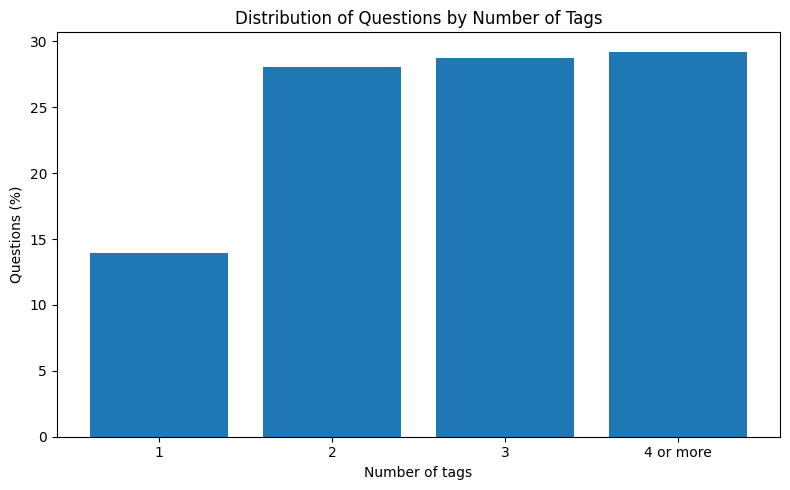

In [47]:
# Q13. What percentage of questions have one, two, three, or more tags?
questions["tag_count"] = (
    questions["tags"].fillna("").str.count(r"<[^>]+>")
)

questions["tag_group"] = questions["tag_count"].apply(
    lambda n: str(n) if n <= 3 else "4 or more"
)

tag_group_counts = questions["tag_group"].value_counts().sort_index()

tag_group_percentages = (
    tag_group_counts / questions["id"].nunique() * 100
)

result_q13 = pd.DataFrame({
    "question_count": tag_group_counts,
    "percentage": tag_group_percentages
})

display(result_q13.round(2))

plt.figure(figsize=(8, 5))
plt.bar(
    result_q13.index,
    result_q13["percentage"]
)
plt.title("Distribution of Questions by Number of Tags")
plt.xlabel("Number of tags")
plt.ylabel("Questions (%)")
plt.tight_layout()
plt.show()

,count,mean,median
status,,,
Duplicate,399974,1.84,0.0
Not marked duplicate,276230,33.40,6.0


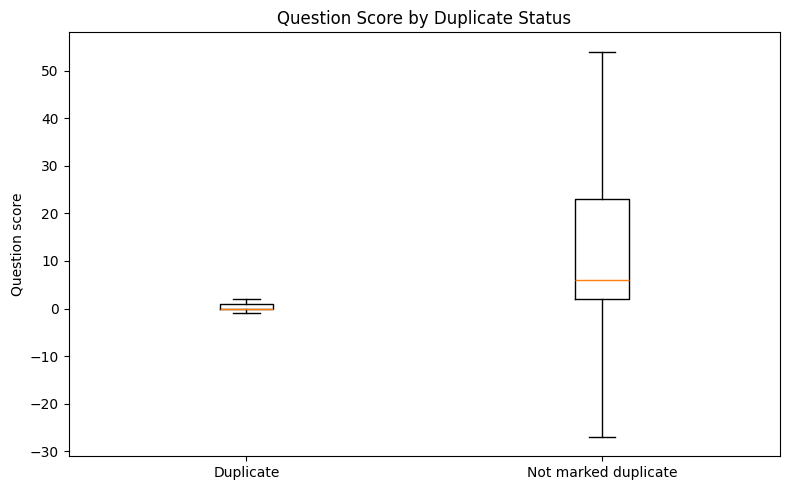

In [48]:
# Q14. What is the relationship between question score and duplicate status?
# Load question scores
posts_scores = pd.read_csv(
    posts_path,
    usecols=["id", "post_type_id", "score"]
)

posts_scores = posts_scores[
    posts_scores["post_type_id"] == 1
].copy()

posts_scores["status"] = posts_scores["id"].isin(
    duplicate_ids
).map({
    True: "Duplicate",
    False: "Not marked duplicate"
})

score_summary = posts_scores.groupby("status")["score"].agg(
    ["count", "mean", "median"]
)

display(score_summary.round(2))

plt.figure(figsize=(8, 5))

score_data = [
    posts_scores.loc[
        posts_scores["status"] == "Duplicate", "score"
    ].dropna(),
    posts_scores.loc[
        posts_scores["status"] == "Not marked duplicate", "score"
    ].dropna()
]

plt.boxplot(
    score_data,
    tick_labels=["Duplicate", "Not marked duplicate"],
    showfliers=False
)

plt.title("Question Score by Duplicate Status")
plt.ylabel("Question score")
plt.tight_layout()
plt.show()

Top 10 users by duplicate-question count:


,duplicate_questions
owner_user_id,
-999,6435
651174,82
1833945,70
2786156,67
1136700,60
496949,58
1194415,55
1103606,54
179736,53


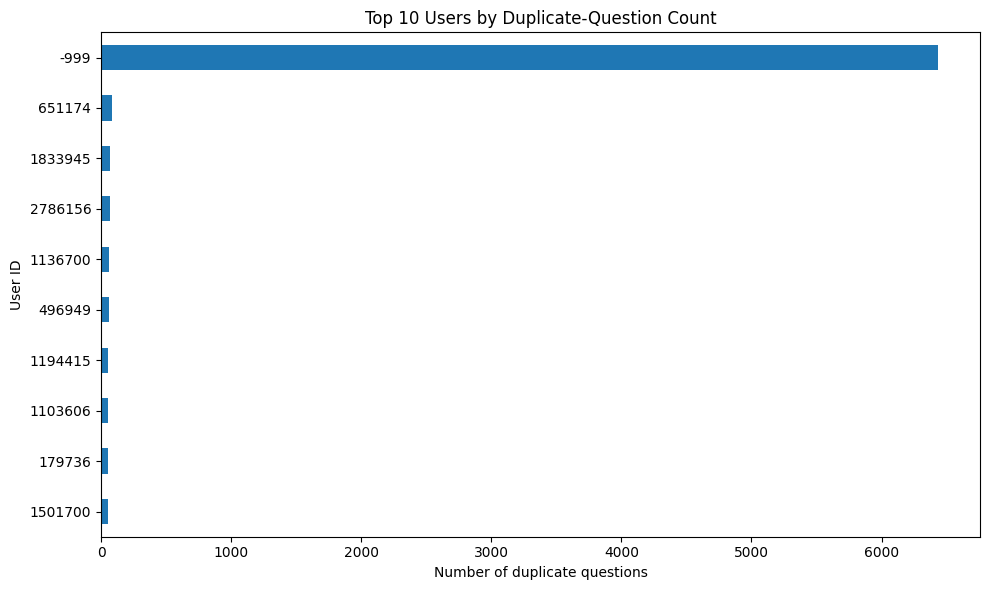

In [49]:
# Q15. How many duplicate questions does each user ask?
# Match duplicate questions with their owners
posts_owners = pd.read_csv(
    posts_path,
    usecols=["id", "post_type_id", "owner_user_id"]
)

duplicate_questions_q15 = posts_owners[
    (posts_owners["post_type_id"] == 1)
    & (posts_owners["id"].isin(duplicate_ids))
    & (posts_owners["owner_user_id"].notna())
].copy()

user_duplicate_counts = (
    duplicate_questions_q15.groupby("owner_user_id")["id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 users by duplicate-question count:")
display(
    user_duplicate_counts.head(10).to_frame(
        "duplicate_questions"
    )
)

user_duplicate_counts.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Users by Duplicate-Question Count",
    xlabel="Number of duplicate questions",
    ylabel="User ID"
)

plt.tight_layout()
plt.show()